In [243]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

from selenium import webdriver
from selenium.webdriver.chrome.service import Service
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
from selenium.webdriver.chrome.options import Options

In [ ]:
# Path ke ChromeDriver
chrome_driver_path = "/Applications/MAMP/htdocs/local/kodingakademi/Python/python 3/final_ds/chromedriver-mac-arm64/chromedriver"

# Konfigurasi opsi Chrome
options = Options()
options.add_argument("--headless=new")  # Jalankan tanpa membuka jendela browser
options.add_argument("--disable-gpu")   # Mengurangi penggunaan GPU
options.add_argument("--no-sandbox")    # Untuk eksekusi di server tanpa GUI
options.add_argument("--disable-dev-shm-usage")  # Untuk menghindari error pada sistem berbasis Linux

# Inisialisasi WebDriver
service = Service(chrome_driver_path)
driver = webdriver.Chrome(service=service, options=options)

# Buka halaman Yahoo Finance
driver.get("https://finance.yahoo.com/quote/BBCA.JK/history/?p=BBCA.JK")

# Tunggu hingga tabel muncul
table = WebDriverWait(driver, 10).until(
    EC.presence_of_element_located((By.CLASS_NAME, "table"))
)

# Ambil semua baris tabel
rows = table.find_elements(By.TAG_NAME, "tr")

data = []
for row in rows:
    cols = row.find_elements(By.TAG_NAME, "td")
    if len(cols) == 7:
        date = cols[0].text 
        open = cols[1].text
        high = cols[2].text 
        low = cols[3].text  
        close = cols[4].text
        adj_close = cols[5].text  
        volume = cols[6].text  
        data.append([date, open, high, low, close, adj_close, volume])

# Simpan dalam DataFrame Pandas
df = pd.DataFrame(data, columns=["Date", "Open", "High", "Low", "Close", "Adj Close", "Volume"])

# Tutup browser
driver.quit()

FUNCTION

In [257]:
# -------------------------
# 1. Load dan Preprocessing
# -------------------------
def preprocess_data(df_raw):
    df = df_raw.copy()
    df['Date'] = df['Date'].astype(str)
    df = df[df['Date'].str.match(r'^[A-Za-z]{3,} \d{1,2}, \d{4}$', na=False)]
    df['Date'] = pd.to_datetime(df['Date'], format='%b %d, %Y')

    # Konversi nilai numerik
    cols = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
    for col in cols:
        df[col] = df[col].str.replace(',', '', regex=False).astype(float)

    # Urutkan dan reset index
    df = df.sort_values('Date').reset_index(drop=True)
    return df

# -------------------------
# 2. Outlier Handling
# -------------------------
def remove_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return df[(df[column] >= lower) & (df[column] <= upper)]

# -------------------------
# 3. Buat Lag Features
# -------------------------
def create_lag_features(series, window):
    df_lag = pd.DataFrame()
    for i in range(1, window + 1):
        df_lag[f'lag_{i}'] = series.shift(i)
    df_lag['target'] = series.values
    df_lag.dropna(inplace=True)
    return df_lag

# -------------------------
# 4. Grid Search Lag Terbaik
# -------------------------
def grid_search_best_lag(df, test_size=7, window_options=[i + 1 for i in range(20)]):
    df = df.reset_index(drop=True)
    df_train = df[:-test_size]
    df_test = df[-test_size:]

    results = []

    for window in window_options:
        df_ml = create_lag_features(df_train['Close'], window)
        if df_ml.shape[0] == 0:
            continue  # Skip jika data kurang

        X = df_ml.drop(columns='target')
        y = df_ml[['target']]

        scaler_x = MinMaxScaler()
        scaler_y = MinMaxScaler()
        X_scaled = scaler_x.fit_transform(X)
        y_scaled = scaler_y.fit_transform(y).ravel()

        x_train, x_val, y_train, y_val = train_test_split(X_scaled, y_scaled, test_size=0.2, random_state=42)

        model = RandomForestRegressor(n_estimators=100, random_state=42)
        model.fit(x_train, y_train)

        # Forecast ke depan (test set size)
        last_values = df_train['Close'].values[-window:]
        forecast_scaled = []

        for _ in range(test_size):
            input_vals = np.array(last_values[-window:]).reshape(1, -1)
            input_df = pd.DataFrame(input_vals, columns=X.columns)
            input_scaled = scaler_x.transform(input_df)
            pred_scaled = model.predict(input_scaled)[0]
            pred_unscaled = scaler_y.inverse_transform([[pred_scaled]])[0][0]
            forecast_scaled.append(pred_unscaled)
            last_values = np.append(last_values, pred_unscaled)

        rmse = np.sqrt(mean_squared_error(df_test['Close'], forecast_scaled))
        results.append((window, rmse))

    return results

# -------------------------
# 5. Visualisasi Hasil Grid Search
# -------------------------
def plot_grid_results(results):
    windows, rmses = zip(*results)
    plt.figure(figsize=(10, 5))
    plt.plot(windows, rmses, marker='o')
    plt.title("Evaluasi Jumlah Lag berdasarkan d_test_rmse")
    plt.xlabel("Jumlah Lag (window)")
    plt.ylabel("RMSE pada Data Test")
    plt.grid(True)
    
    # Tampilkan semua nilai X (jumlah lag)
    plt.xticks(windows)  # tampilkan semua label x-axis sesuai windows yang diuji
    
    plt.tight_layout()
    plt.show()



FORECASTING MACHINE LEARNING

In [258]:
df_backup = preprocess_data(df)
df_backup = remove_outliers_iqr(df_backup, 'Close')
df_backup

,Date,Open,High,Low,Close,Adj Close,Volume
0,2024-05-16,9575.0,9675.0,9525.0,9600.0,9267.21,61126000.0
1,2024-05-17,9600.0,9850.0,9575.0,9750.0,9412.01,99848500.0
2,2024-05-20,9700.0,9800.0,9475.0,9475.0,9146.54,87890100.0
3,2024-05-21,9450.0,9575.0,9375.0,9375.0,9050.01,75311400.0
4,2024-05-22,9475.0,9575.0,9325.0,9425.0,9098.28,121712700.0
...,...,...,...,...,...,...,...
233,2025-05-08,9075.0,9200.0,8925.0,8975.0,8975.00,99614500.0
234,2025-05-09,9050.0,9050.0,8975.0,9000.0,9000.00,47167500.0
235,2025-05-14,9250.0,9300.0,9150.0,9275.0,9275.00,149002900.0
236,2025-05-15,9275.0,9400.0,9250.0,9275.0,9275.00,101401300.0


Best lag window: 2


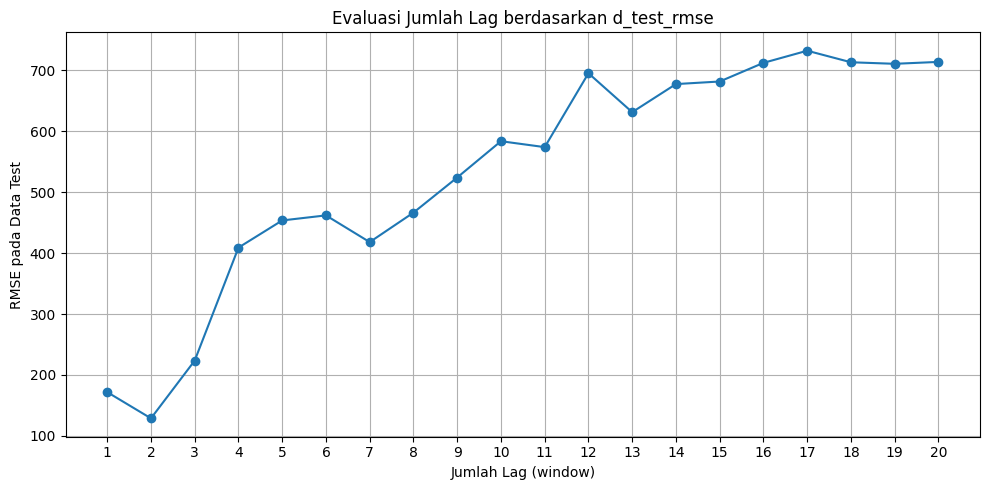

In [259]:
window = grid_search_best_lag(df_backup)
best_window = min(window, key=lambda x: x[1])[0]  # Ambil window dengan RMSE terkecil
print(f"Best lag window: {best_window}")

plot_grid_results(window)

In [260]:
df_ml = create_lag_features(df_backup['Close'], best_window)
df_ml

,lag_1,lag_2,target
2,9750.0,9600.0,9475.0
3,9475.0,9750.0,9375.0
4,9375.0,9475.0,9425.0
5,9425.0,9375.0,9300.0
6,9300.0,9425.0,9300.0
...,...,...,...
233,9075.0,9025.0,8975.0
234,8975.0,9075.0,9000.0
235,9000.0,8975.0,9275.0
236,9275.0,9000.0,9275.0


In [261]:
x = df_ml.drop('target', axis=1)
y = df_ml[['target']]

scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()

scale_x = scaler_x.fit_transform(x)
scale_y = scaler_y.fit_transform(y).ravel()

x_train, x_test, y_train, y_test = train_test_split(scale_x, scale_y, test_size=0.2, random_state=42)


In [262]:
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(x_train, y_train)

RandomForestRegressor(random_state=42)

In [263]:
y_pred = model.predict(x_test)
model_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print("Skor model RMSE :", model_rmse)

Skor model RMSE : 0.06485998350881218


In [266]:
n_future = 7
last_values = df_backup['Close'].values[-best_window:]  # perbaikan di sini

forecast_scaled = []

for _ in range(n_future):
    input_vals = np.array(last_values[-best_window:]).reshape(1, -1)
    input_df = pd.DataFrame(input_vals, columns=x.columns)  
    input_scaled = scaler_x.transform(input_df)
    pred_scaled = model.predict(input_scaled)[0]  
    forecast_scaled.append(pred_scaled)

    pred_unscaled = scaler_y.inverse_transform([[pred_scaled]])[0][0]
    last_values = np.append(last_values, pred_unscaled)

forecast_unscaled = [scaler_y.inverse_transform([[val]])[0][0] for val in forecast_scaled]

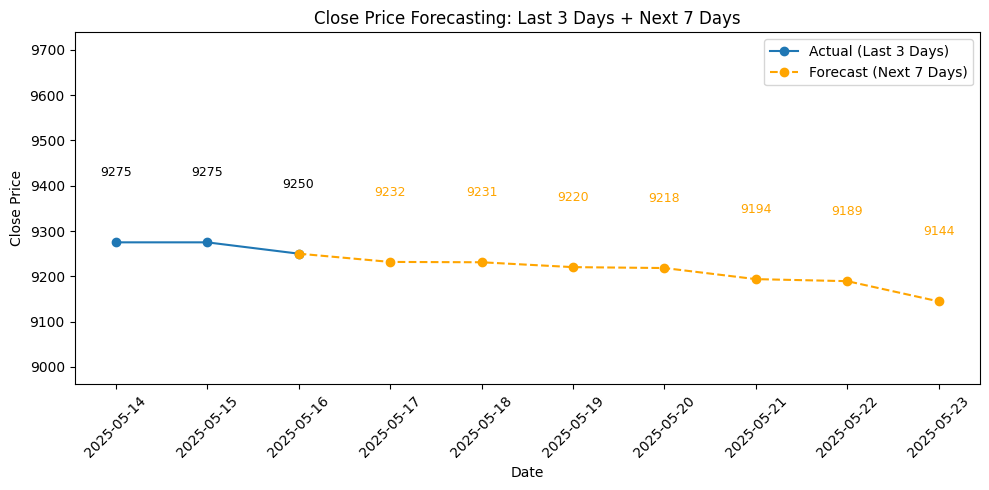

In [267]:
last_3_dates = df_backup['Date'].iloc[-3:].tolist()
last_3_close = df_backup['Close'].iloc[-3:].tolist()

# Ambil tanggal terakhir
last_date = df_backup['Date'].iloc[-1]

# Buat tanggal untuk 7 hari ke depan
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=n_future, freq='D').tolist()

# Sisipkan titik terakhir histori ke awal prediksi (agar garis forecast nyambung)
forecast_dates_full = [last_3_dates[-1]] + future_dates
forecast_values_full = [last_3_close[-1]] + forecast_unscaled

# Gabungkan semua tanggal yang ingin ditampilkan di sumbu X
all_dates = last_3_dates + future_dates

# --- Visualisasi ---
plt.figure(figsize=(10, 5))

# Plot data historis
plt.plot(last_3_dates, last_3_close, label='Actual (Last 3 Days)', linestyle='-', marker='o')

# Plot forecast (disambung dari titik terakhir histori)
plt.plot(forecast_dates_full, forecast_values_full, label='Forecast (Next 7 Days)', linestyle='--', marker='o', color='orange')

# Hitung batas atas untuk y-axis agar label muat
all_y_values = last_3_close + forecast_values_full[1:]
y_max = max(all_y_values)
y_min = min(all_y_values)
plt.ylim(y_min * 0.98, y_max * 1.05)  # beri margin atas dan bawah

# Tambahkan label angka untuk actual
for date, value in zip(last_3_dates, last_3_close):
    offset = y_max * 0.015  # offset agar tidak bertabrakan dengan titik
    plt.text(date, value + offset, f'{value:.0f}', ha='center', va='bottom', fontsize=9)

# Tambahkan label angka untuk forecast (lewati titik sambungan)
for date, value in zip(forecast_dates_full[1:], forecast_values_full[1:]):
    offset = y_max * 0.015
    plt.text(date, value + offset, f'{value:.0f}', ha='center', va='bottom', fontsize=9, color='orange')

# Format plot
plt.title('Close Price Forecasting: Last 3 Days + Next 7 Days')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.xticks(ticks=all_dates, rotation=45)
plt.tight_layout()
plt.show()